# Analisis Spasial & Kelayakan Buka Kafe di Sekitar Kampus Surabaya

**Mata Kuliah:** Computer Graphics (AFL 2) — Program Studi Informatika, Universitas Ciputra Surabaya (T.A. 2026/2027)  
**Dokumen Proposal Acuan:** `Proposal AFL 2 Computer Graphics.pdf`  
**Tim Pengembang:**
- Filemon Jose Hagen (0706012410016)
- Hafizd Dharma Saputra Hardiono (0706012410023)
- Flabianos Jason Muljono (0706012410019)

---

### ⚠️ Pemberitahuan Atribusi & Integritas Metodologis (Task 2 Attribution Fix):
1. **Atribusi Observasi Google Street View:** Sebanyak 16 titik observasi kandidat lahan dalam studi ini **diobservasi oleh Agen AI (Claude) melalui peramban desktop Dharma atas permintaan anggota tim pada 1 November 2026**.
2. **Kebutuhan Peninjauan Tim:** Seluruh 16 titik observasi ini **wajib ditinjau ulang oleh seluruh anggota tim (*requires team review*)** sebelum diputuskan untuk langkah bisnis riil.
3. **Bukan Survei Lapangan Manusia:** Data ini **BUKAN hasil survei lapangan fisik langsung oleh tim manusia (*not human team field survey*)**, melainkan penelusuran citra visual daring Google Street View dengan pencatatan `pano_id`, arah kamera `heading_deg`, dan koordinat kamera.
4. **Prinsip Anti-Fabrikasi:** Nilai luas tanah dan harga sewa pada data observasi visual diisi `None` (*null*) karena citra kamera tidak mencantumkan kontrak sewa terverifikasi. Tidak ada titik gerbang kampus (*campus gates*) atau jalan raya baru yang difabrikasi.

In [1]:
import os
import sys
import json
import csv
import math
from pathlib import Path

# Resolusi path repositori relatif (tanpa path absolut pengguna)
cwd = Path.cwd().resolve()
if (cwd / "scripts" / "gis_pipeline.py").exists():
    REPO_ROOT = cwd
elif (cwd.parent / "scripts" / "gis_pipeline.py").exists():
    REPO_ROOT = cwd.parent
else:
    raise FileNotFoundError("Direktori root repositori tidak dapat ditemukan!")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Impor pipeline GIS dan fungsi skor kelayakan transparan
from scripts.gis_pipeline import (
    GISPipeline,
    BASELINE_RADIUS_METERS,
    SCENARIO_RADIUS_METERS,
    RADIUS_CONFIG,
    VALID_LAND_STATUSES,
    ELIGIBLE_STATUSES,
    RENTABLE_OR_SALE_STATUSES,
    NON_RENTABLE_OR_SALE_STATUSES,
    TEAM_SCORING_ASSUMPTIONS,
    calculate_transparent_feasibility_score,
    CAMPUS_POLYGONS_WGS84
)

print(f"✓ Root repositori terdeteksi : {REPO_ROOT.name}")
print(f"✓ Baseline buffer radius    : {BASELINE_RADIUS_METERS} meter (fokus jalan kaki pejalan kaki)")
print(f"✓ Scenario buffer radius    : {SCENARIO_RADIUS_METERS} meter (skenario jangkauan luas)")
print(f"✓ Status lahan valid        : {len(VALID_LAND_STATUSES)} status baku")
print(f"✓ Status memenuhi syarat    : {ELIGIBLE_STATUSES}")

✓ Root repositori terdeteksi : Comgraph-AFL-2
✓ Baseline buffer radius    : 500.0 meter (fokus jalan kaki pejalan kaki)
✓ Scenario buffer radius    : 1000.0 meter (skenario jangkauan luas)
✓ Status lahan valid        : 5 status baku
✓ Status memenuhi syarat    : {'Lahan yang tersedia untuk disewakan', 'Lahan kosong'}


## 1. Tabel Metadata Seluruh Lapisan Spasial WebGIS
Sistem pemetaan interaktif "Buka Kafe" mengelola multi-lapisan data spasial yang memisahkan antara batas kampus OSM, zona penyangga (*dual buffer*), kafe eksisting, observasi faktual Street View, listing sewa publik, dan skenario simulasi.

In [2]:
# Tabel Metadata Seluruh Lapisan Spasial
layers_meta = [
    {
        "Nama Layer": "Titik Kampus (Centroid)",
        "Path Berkas": "data/raw/universities.geojson",
        "Sumber": "OpenStreetMap & Nominatim",
        "Fitur": 8,
        "CRS": "EPSG:4326 (WGS84)",
        "Peran Sistem": "Titik acuan pusat kampus (centroid)"
    },
    {
        "Nama Layer": "Perimeter Poligon Kampus",
        "Path Berkas": "data/processed/universities_polygons.geojson",
        "Sumber": "OpenStreetMap Ways & Relations",
        "Fitur": 8,
        "CRS": "EPSG:4326 & EPSG:32749",
        "Peran Sistem": "Batas kadaster perimeter universitas"
    },
    {
        "Nama Layer": "Buffer Baseline 500m (Radial)",
        "Path Berkas": "data/processed/buffer_500m.geojson",
        "Sumber": "GISPipeline Dilatasi Metrik",
        "Fitur": 8,
        "CRS": "EPSG:4326 (Metrik 32749)",
        "Peran Sistem": "Batas utama pejalan kaki (Default ON)"
    },
    {
        "Nama Layer": "Buffer Skenario 1000m (Radial)",
        "Path Berkas": "data/processed/buffer_1000m.geojson",
        "Sumber": "GISPipeline Dilatasi Metrik",
        "Fitur": 8,
        "CRS": "EPSG:4326 (Metrik 32749)",
        "Peran Sistem": "Jangkauan strategis luas (Default OFF)"
    },
    {
        "Nama Layer": "Kandidat Lahan Observasi",
        "Path Berkas": "data/raw/survey_land_candidates.geojson",
        "Sumber": "Google Street View (Claude & Dharma)",
        "Fitur": 16,
        "CRS": "EPSG:4326",
        "Peran Sistem": "Observasi visual riil (4 eligible, 12 inel)"
    },
    {
        "Nama Layer": "Kafe Eksisting Surabaya",
        "Path Berkas": "data/raw/osm/osm_cafes.geojson",
        "Sumber": "OpenStreetMap ODbL 1.0",
        "Fitur": 206,
        "CRS": "EPSG:4326",
        "Peran Sistem": "Peta kompetisi kafe (59 dlm buffer)"
    },
    {
        "Nama Layer": "Skenario Simulasi Hipotetis",
        "Path Berkas": "data/fixtures/synthetic_scenario_candidates.geojson",
        "Sumber": "Generator Skenario Sintetis",
        "Fitur": 8,
        "CRS": "EPSG:4326",
        "Peran Sistem": "Pengujian algoritma perencana (Opt-in)"
    },
    {
        "Nama Layer": "Listing Bukti Sewa Riil",
        "Path Berkas": "data/raw/rental_listing_evidence.csv",
        "Sumber": "Ray White & Rumah123 Langsung",
        "Fitur": 15,
        "CRS": "Teks Alamat / Koridor",
        "Peran Sistem": "Katalog bukti harga pasar komersial"
    }
]

print(f"{'Nama Layer':<32} | {'Fitur':<6} | {'Sistem Koordinat':<24} | {'Peran Sistem'}")
print("-" * 105)
for lyr in layers_meta:
    print(f"{lyr['Nama Layer']:<32} | {lyr['Fitur']:<6} | {lyr['CRS']:<24} | {lyr['Peran Sistem']}")
print("-" * 105)

Nama Layer                       | Fitur  | Sistem Koordinat         | Peran Sistem
---------------------------------------------------------------------------------------------------------
Titik Kampus (Centroid)          | 8      | EPSG:4326 (WGS84)        | Titik acuan pusat kampus (centroid)
Perimeter Poligon Kampus         | 8      | EPSG:4326 & EPSG:32749   | Batas kadaster perimeter universitas
Buffer Baseline 500m (Radial)    | 8      | EPSG:4326 (Metrik 32749) | Batas utama pejalan kaki (Default ON)
Buffer Skenario 1000m (Radial)   | 8      | EPSG:4326 (Metrik 32749) | Jangkauan strategis luas (Default OFF)
Kandidat Lahan Observasi         | 16     | EPSG:4326                | Observasi visual riil (4 eligible, 12 inel)
Kafe Eksisting Surabaya          | 206    | EPSG:4326                | Peta kompetisi kafe (59 dlm buffer)
Skenario Simulasi Hipotetis      | 8      | EPSG:4326                | Pengujian algoritma perencana (Opt-in)
Listing Bukti Sewa Riil          | 15     | 

## 2. Eksekusi Pipeline GIS Dual-Radius (Baseline 500m & Skenario 1.000m)
Menjalankan pipeline GIS metrik EPSG:32749 untuk membangkitkan buffer radial dan buffer dilatasi poligon, serta mengevaluasi posisi seluruh kandidat lahan dan kafe eksisting terhadap kedua ambang radius.

In [3]:
pipeline = GISPipeline()
uni_path = REPO_ROOT / "data" / "raw" / "universities.geojson"
candidates_path = REPO_ROOT / "data" / "raw" / "survey_land_candidates.geojson"
output_dir = REPO_ROOT / "data" / "processed"

pipeline_result = pipeline.process(
    universities_path=str(uni_path),
    candidates_path=str(candidates_path),
    output_dir=str(output_dir)
)

print("=== HASIL EKSEKUSI PIPELINE GIS METRIK ===")
print(f"Total Kampus Sasaran       : {pipeline_result['universities_count']} kampus")
print(f"Total Buffer Radial (Dual) : {pipeline_result['buffers_count']} geometri")
print(f"Total Buffer Poligon (Dual): {pipeline_result['polygon_buffers_count']} geometri")
print(f"Total Kandidat Lahan       : {pipeline_result['candidates_count']} observasi Street View")
print(f"Total Kafe OSM di Surabaya : {pipeline_result['cafes_count']} titik")
print(f"Kafe OSM dalam Buffer      : {pipeline_result['cafes_in_buffer_count']} titik")
print("\nStatistik Kelayakan Kandidat Lahan:")
for k, v in pipeline_result['stats'].items():
    if k != 'status_counts':
        print(f"  - {k:<25}: {v}")
print("\nDistribusi Status Lahan Faktual:")
for status, count in pipeline_result['stats']['status_counts'].items():
    print(f"  * {status:<45}: {count} lokasi")

=== HASIL EKSEKUSI PIPELINE GIS METRIK ===
Total Kampus Sasaran       : 8 kampus
Total Buffer Radial (Dual) : 8 geometri
Total Buffer Poligon (Dual): 8 geometri
Total Kandidat Lahan       : 16 observasi Street View
Total Kafe OSM di Surabaya : 206 titik
Kafe OSM dalam Buffer      : 59 titik

Statistik Kelayakan Kandidat Lahan:
  - total_candidates         : 16
  - in_buffer_count          : 16
  - in_buffer_500m_count     : 15
  - in_buffer_1000m_count    : 16
  - out_of_buffer_count      : 0
  - out_of_buffer_500m_count : 1
  - out_of_buffer_1000m_count: 0
  - eligible_count           : 4
  - eligible_500m_count      : 4
  - eligible_1000m_count     : 4
  - ineligible_count         : 12
  - ineligible_500m_count    : 12
  - ineligible_1000m_count   : 12
  - rentable_or_sale_count   : 4
  - non_rentable_or_sale_count: 12

Distribusi Status Lahan Faktual:
  * Lahan kosong                                 : 3 lokasi
  * Lahan yang tersedia untuk disewakan          : 1 lokasi
  * Rumah ata

## 3. Tabel Analisis Sebaran Dual Radius per Kampus
Memetakan perbandingan jumlah kafe eksisting OpenStreetMap dan kandidat lahan observasi Street View pada radius baseline 500 meter (standar jalan kaki Bab 1.1 proposal) dibandingkan skenario 1.000 meter (jangkauan luas Bab 2.2 proposal) untuk setiap kampus.

In [4]:
with open(output_dir / "osm_cafes.geojson", "r", encoding="utf-8") as f:
    cafes_geojson = json.load(f)

with open(output_dir / "land_candidates.geojson", "r", encoding="utf-8") as f:
    candidates_geojson = json.load(f)

with open(uni_path, "r", encoding="utf-8") as f:
    unis_geojson = json.load(f)

campuses = [u["properties"] for u in unis_geojson["features"]]
cafe_items = [c["properties"] for c in cafes_geojson["features"]]
cand_items = [c["properties"] for c in candidates_geojson["features"]]

print(f"{'ID Kampus':<16} | {'Nama Kampus':<36} | {'Kafe <=500m':<11} | {'Kafe <=1km':<11} | {'Kandidat <=500m':<15} | {'Kandidat <=1km'}")
print("-" * 115)
for camp in campuses:
    cid = camp["id"]
    cname = camp["campus_name"]
    # Kafe
    c_500 = sum(1 for c in cafe_items if c.get("nearest_university_id") == cid and c.get("distance_meters", 9999) <= 500.0)
    c_1000 = sum(1 for c in cafe_items if c.get("nearest_university_id") == cid and c.get("distance_meters", 9999) <= 1000.0)
    # Kandidat Lahan
    k_500 = sum(1 for k in cand_items if k.get("nearest_university_id") == cid and k.get("distance_meters", 9999) <= 500.0)
    k_1000 = sum(1 for k in cand_items if k.get("nearest_university_id") == cid and k.get("distance_meters", 9999) <= 1000.0)
    print(f"{cid:<16} | {cname:<36} | {c_500:<11} | {c_1000:<11} | {k_500:<15} | {k_1000}")
print("-" * 115)

ID Kampus        | Nama Kampus                          | Kafe <=500m | Kafe <=1km  | Kandidat <=500m | Kandidat <=1km
-------------------------------------------------------------------------------------------------------------------
UNAIR-KAMPUS-A   | Kampus A Universitas Airlangga       | 2           | 14          | 2               | 2
UNAIR-KAMPUS-B   | Kampus B Universitas Airlangga       | 8           | 14          | 2               | 2
UNAIR-KAMPUS-C   | Kampus C Universitas Airlangga       | 0           | 0           | 1               | 2
UKWMS-DINOYO     | Universitas Katolik Widya Mandala Surabaya Kampus Dinoyo | 4           | 17          | 2               | 2
UKWMS-KALIJUDAN  | Universitas Katolik Widya Mandala Surabaya Kampus Kalijudan | 1           | 2           | 1               | 1
UKWMS-PAKUWON    | Universitas Katolik Widya Mandala Surabaya Kampus Pakuwon City | 0           | 1           | 2               | 2
UBAYA-NGAGEL     | Universitas Surabaya Kampus Ngagel   | 5 

## 4. Pemeringkatan Kandidat Lahan & Skor Kelayakan Transparan (*Rankings with Coverage*)
Sesuai mandat anti-fabrikasi, sistem **tidak pernah menebak harga sewa (*never guess rent*)**. Komponen yang belum diobservasi (`rental_price_yr: null` atau `area_sqm: null`) dikeluarkan dari pembagi bobot dan skor dinormalisasi secara proporsional ke skala 0–100.

In [5]:
ranked_candidates = []
for feat in candidates_geojson["features"]:
    p = feat["properties"]
    score_res = calculate_transparent_feasibility_score(
        distance_meters=p.get("distance_meters"),
        area_sqm=p.get("area_sqm"),
        rental_price_yr=p.get("rental_price_yr"),
        radius_mode="baseline_500m"
    )
    ranked_candidates.append({
        "id": p["id"],
        "name": p["name"],
        "campus": p["nearest_university_id"],
        "dist_m": p["distance_meters"],
        "status": p["status"],
        "eligible": p["is_eligible"],
        "score": score_res["score_normalized"],
        "grade": score_res["grade"],
        "coverage": f"{len(score_res['observed_components'])}/3 ({', '.join(score_res['observed_components'])})",
        "nearest_cafe": p.get("nearest_cafe_name") or "Tidak terdeteksi",
        "nearest_cafe_dist": p.get("nearest_cafe_distance_meters")
    })

# Urutkan: Eligible terlebih dahulu, kemudian skor tertinggi
ranked_candidates.sort(key=lambda x: (not x["eligible"], -(x["score"] or 0)))

print(f"{'No':<3} | {'ID':<22} | {'Kampus':<16} | {'Jarak':<8} | {'Status Lahan':<32} | {'Skor':<6} | {'Grade':<20} | {'Coverage'}")
print("-" * 130)
for i, r in enumerate(ranked_candidates, 1):
    dist_str = f"{r['dist_m']:.1f}m" if r['dist_m'] else "-"
    score_str = f"{r['score']:.1f}" if r['score'] is not None else "-"
    print(f"{i:<3} | {r['id']:<22} | {r['campus']:<16} | {dist_str:<8} | {r['status']:<32} | {score_str:<6} | {r['grade']:<20} | {r['coverage']}")
print("-" * 130)

No  | ID                     | Kampus           | Jarak    | Status Lahan                     | Skor   | Grade                | Coverage
----------------------------------------------------------------------------------------------------------------------------------
1   | SV-UKWMS-PAKUWON-01    | UKWMS-PAKUWON    | 258.6m   | Lahan kosong                     | 75.0   | Strategis ★★         | 1/3 (proximity)
2   | SV-UBAYA-TENGGILIS-01  | UBAYA-TENGGILIS  | 238.7m   | Lahan kosong                     | 75.0   | Strategis ★★         | 1/3 (proximity)
3   | SV-UNAIR-C-02          | UNAIR-KAMPUS-C   | 465.8m   | Lahan yang tersedia untuk disewakan | 50.0   | Cukup Layak ★        | 1/3 (proximity)
4   | SV-UKWMS-PAKUWON-02    | UKWMS-PAKUWON    | 474.4m   | Lahan kosong                     | 50.0   | Cukup Layak ★        | 1/3 (proximity)
5   | SV-UKWMS-KALIJUDAN-01  | UKWMS-KALIJUDAN  | 145.7m   | Rumah atau bangunan tempat tinggal | 100.0  | Sangat Strategis ★★★ | 1/3 (proximity)
6   | S

## 5. Visualisasi Spasial Statis Matplotlib
Peta 2 dimensi statis yang menyajikan sebaran geografis 8 kampus sasaran di Surabaya, zona penyangga baseline 500 meter (garis solid biru), skenario 1.000 meter (garis putus-putus ungu), 206 kafe eksisting OpenStreetMap, serta 16 kandidat lahan observasi Street View.

Matplotlib is building the font cache; this may take a moment.


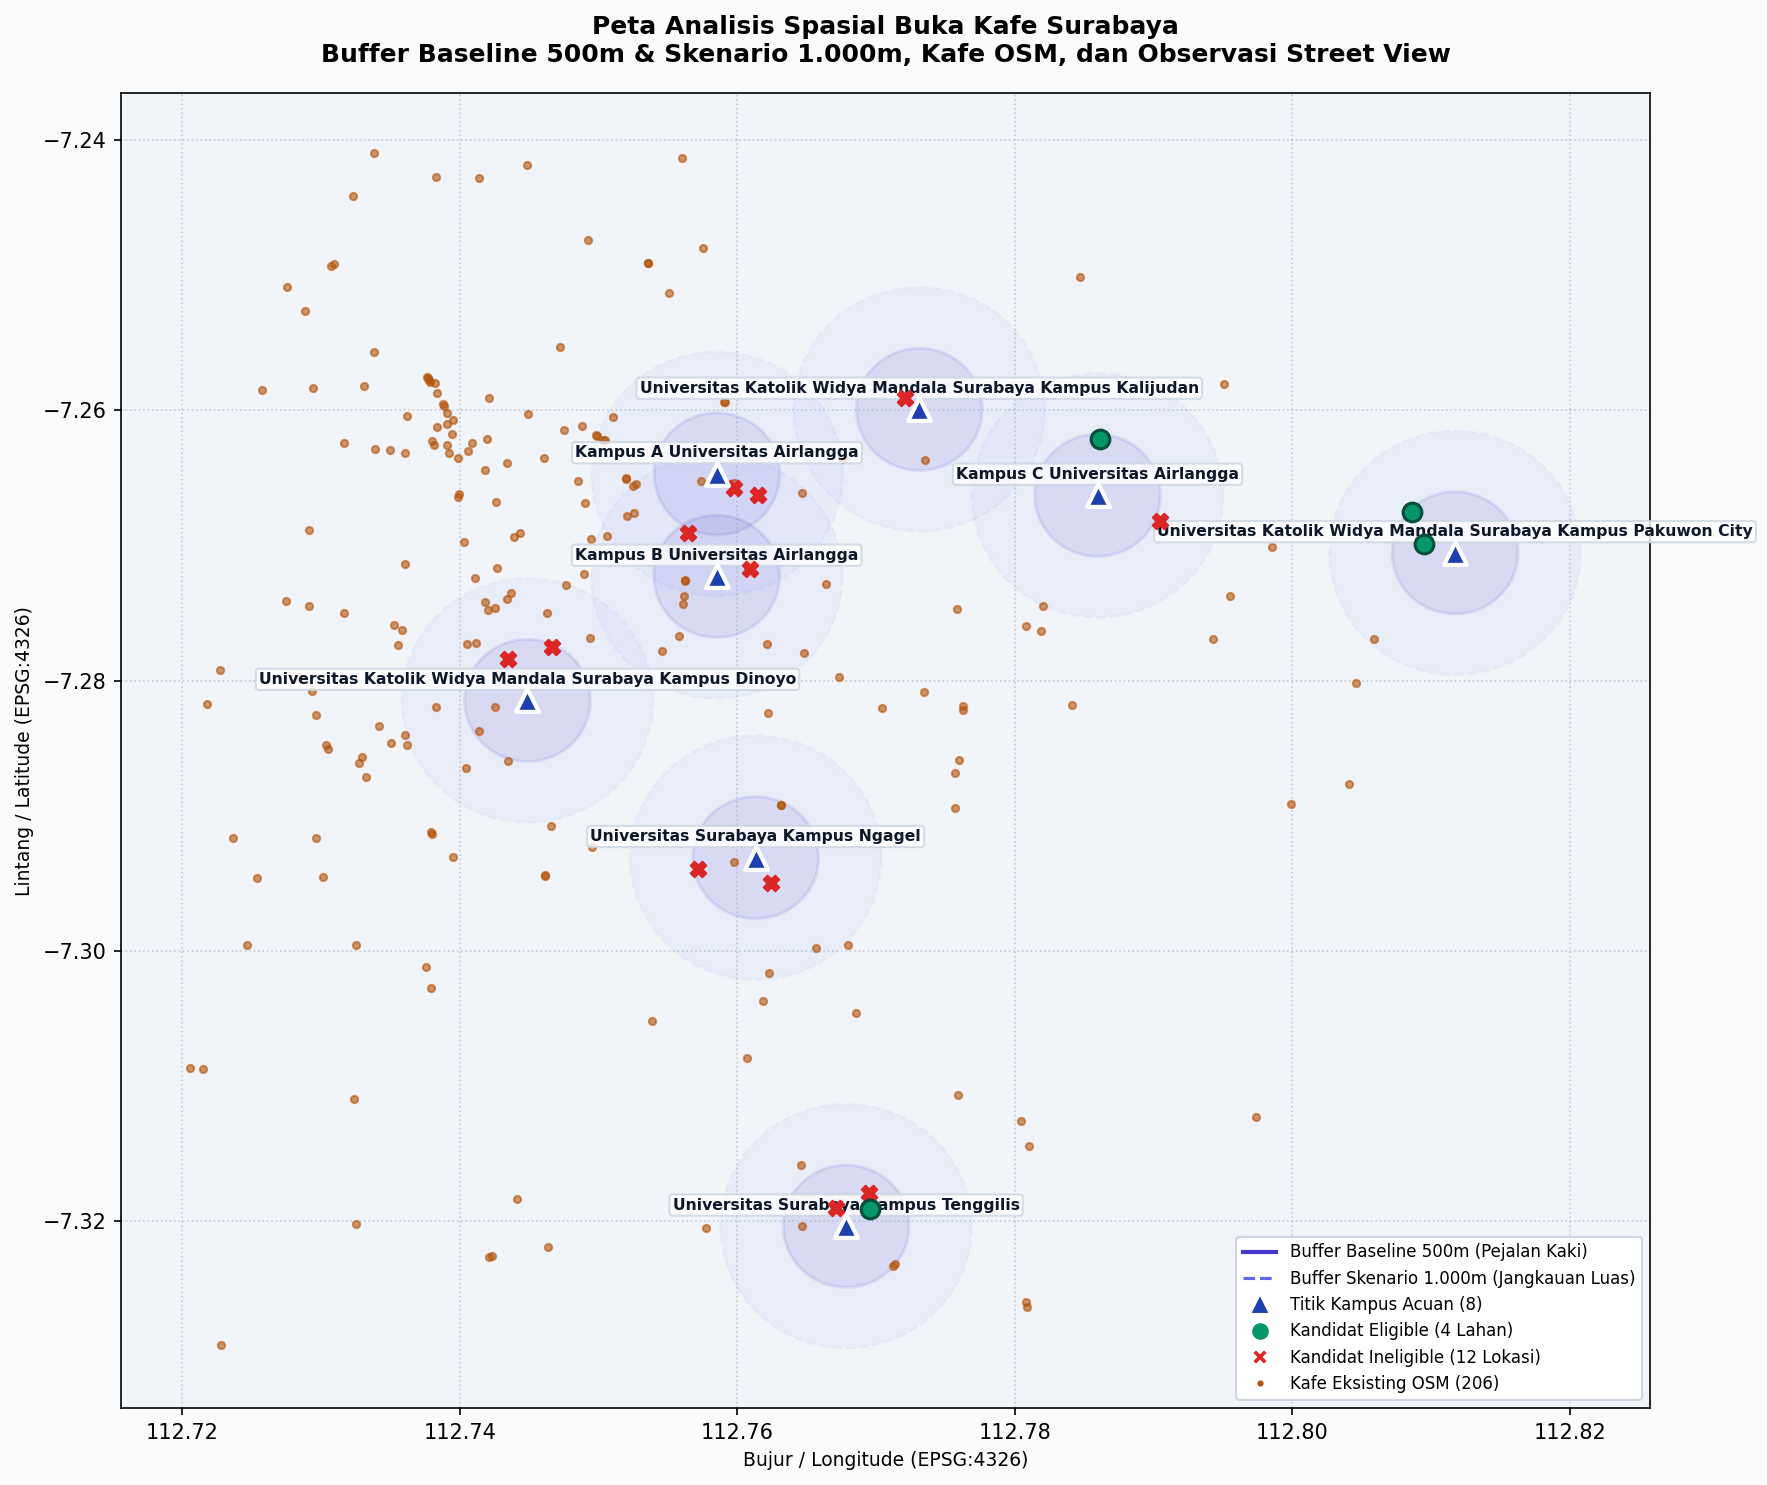

✓ Peta statis berhasil disimpan ke: peta_analisis_spasial.png


In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(12, 10), dpi=150)
fig.patch.set_facecolor('#F8FAFC')
ax.set_facecolor('#F1F5F9')

# 1. Plot Buffer Skenario 1.000m (Garis putus-putus ungu)
with open(output_dir / "buffer_1000m.geojson", "r", encoding="utf-8") as f:
    buf1000 = json.load(f)
for feat in buf1000["features"]:
    geom = feat["geometry"]
    coords = geom["coordinates"][0]
    poly = MplPolygon(coords, closed=True, facecolor='#6366F1', alpha=0.05, edgecolor='#6366F1', linestyle='--', linewidth=1.2)
    ax.add_patch(poly)

# 2. Plot Buffer Baseline 500m (Garis solid indigo)
with open(output_dir / "buffer_500m.geojson", "r", encoding="utf-8") as f:
    buf500 = json.load(f)
for feat in buf500["features"]:
    geom = feat["geometry"]
    coords = geom["coordinates"][0]
    poly = MplPolygon(coords, closed=True, facecolor='#4338CA', alpha=0.10, edgecolor='#4338CA', linestyle='-', linewidth=1.5)
    ax.add_patch(poly)

# 3. Plot Kafe Eksisting OpenStreetMap (titik cokelat kecil)
cafe_lons = [feat["geometry"]["coordinates"][0] for feat in cafes_geojson["features"]]
cafe_lats = [feat["geometry"]["coordinates"][1] for feat in cafes_geojson["features"]]
ax.scatter(cafe_lons, cafe_lats, color='#B45309', s=12, alpha=0.6, label='Kafe Eksisting OSM (206)', zorder=3)

# 4. Plot Kandidat Lahan Observasi Street View
el_lons = [f["geometry"]["coordinates"][0] for f in candidates_geojson["features"] if f["properties"]["is_eligible"]]
el_lats = [f["geometry"]["coordinates"][1] for f in candidates_geojson["features"] if f["properties"]["is_eligible"]]
inel_lons = [f["geometry"]["coordinates"][0] for f in candidates_geojson["features"] if not f["properties"]["is_eligible"]]
inel_lats = [f["geometry"]["coordinates"][1] for f in candidates_geojson["features"] if not f["properties"]["is_eligible"]]

ax.scatter(inel_lats and inel_lons, inel_lats, color='#DC2626', marker='X', s=55, label='Kandidat Ineligible (12 - Rumah/Usaha)', zorder=5)
ax.scatter(el_lons, el_lats, color='#059669', marker='o', s=80, edgecolors='#064E3B', linewidths=1.5, label='Kandidat Eligible (4 - Kosong/Sewa)', zorder=6)

# 5. Plot Titik Kampus Utama
u_lons = [u["geometry"]["coordinates"][0] for u in unis_geojson["features"]]
u_lats = [u["geometry"]["coordinates"][1] for u in unis_geojson["features"]]
ax.scatter(u_lons, u_lats, color='#1E40AF', marker='^', s=120, edgecolors='#FFFFFF', linewidths=2, label='Titik Kampus Acuan (8)', zorder=7)

for u in unis_geojson["features"]:
    props = u["properties"]
    lon, lat = u["geometry"]["coordinates"]
    ax.annotate(props["campus_name"], (lon, lat), textcoords="offset points", xytext=(0, 8),
                ha='center', fontsize=7.5, fontweight='bold', color='#0F172A',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='#CBD5E1'))

ax.set_title("Peta Analisis Spasial Buka Kafe Surabaya\nBuffer Baseline 500m & Skenario 1.000m, Kafe OSM, dan Observasi Street View", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Bujur / Longitude (EPSG:4326)", fontsize=9)
ax.set_ylabel("Lintang / Latitude (EPSG:4326)", fontsize=9)
ax.grid(True, linestyle=':', alpha=0.5, color='#94A3B8')

# Custom Legend
legend_elements = [
    Line2D([0], [0], color='#4338CA', lw=2, linestyle='-', label='Buffer Baseline 500m (Pejalan Kaki)'),
    Line2D([0], [0], color='#6366F1', lw=1.5, linestyle='--', label='Buffer Skenario 1.000m (Jangkauan Luas)'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='#1E40AF', markersize=10, label='Titik Kampus Acuan (8)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#059669', markersize=9, label='Kandidat Eligible (4 Lahan)'),
    Line2D([0], [0], marker='X', color='w', markerfacecolor='#DC2626', markersize=8, label='Kandidat Ineligible (12 Lokasi)'),
    Line2D([0], [0], marker='.', color='w', markerfacecolor='#B45309', markersize=8, label='Kafe Eksisting OSM (206)')
]
ax.legend(handles=legend_elements, loc='lower right', framealpha=0.95, edgecolor='#CBD5E1', fontsize=8)

map_png_path = REPO_ROOT / "notebooks" / "peta_analisis_spasial.png"
plt.tight_layout()
plt.savefig(map_png_path, dpi=200)
plt.show()
print(f"✓ Peta statis berhasil disimpan ke: {map_png_path.name}")

## 6. Ekspor Berkas Data Terobservasi & Ringkasan Transparan
Seluruh hasil observasi diekspor ke format CSV terstandarisasi (`valid_observed_candidates.csv` dan `rental_listing_evidence.csv`) serta ringkasan `.txt` yang mencantumkan atribusi akurat dan batasan studi.

In [7]:
# Verifikasi berkas ekspor CSV dan TXT
csv_candidates_path = REPO_ROOT / "data" / "processed" / "valid_observed_candidates.csv"
csv_evidence_path = REPO_ROOT / "data" / "raw" / "rental_listing_evidence.csv"
txt_summary_path = REPO_ROOT / "notebooks" / "analisis_summary.txt"

print(f"1. Valid Observed Candidates CSV : {csv_candidates_path.exists()} ({csv_candidates_path.stat().st_size} bytes)")
print(f"2. Rental Listing Evidence CSV    : {csv_evidence_path.exists()} ({csv_evidence_path.stat().st_size} bytes)")
print(f"3. Transparent Summary TXT        : {txt_summary_path.exists()} ({txt_summary_path.stat().st_size} bytes)")

print("\nCuplikan 3 Listing Bukti Sewa Publik Terverifikasi (data/raw/rental_listing_evidence.csv):")
with open(csv_evidence_path, "r", encoding="utf-8") as f:
    reader = csv.reader(f)
    for i, row in enumerate(reader):
        if i > 3:
            break
        print(f"Row {i}: {row[0]:<14} | {row[1]:<16} | HTTP {row[4]} | Rp {row[8]} | {row[7][:40]}...")

1. Valid Observed Candidates CSV : True (9469 bytes)
2. Rental Listing Evidence CSV    : True (8764 bytes)
3. Transparent Summary TXT        : True (3886 bytes)

Cuplikan 3 Listing Bukti Sewa Publik Terverifikasi (data/raw/rental_listing_evidence.csv):
Row 0: listing_id     | corridor_id      | HTTP http_status | Rp stated_rent_per_year_idr | page_title...
Row 1: UNAIR-A-01     | UNAIR-KAMPUS-A   | HTTP 200 | Rp 135000000 | Sewa Ruko Jl Dharmahusada - Dr Moestopo ...
Row 2: UNAIR-A-02     | UNAIR-KAMPUS-A   | HTTP 200 | Rp 75000000 | Disewa Disewakan Ruko 2 lantai di Jl Pac...
Row 3: UNAIR-B-01     | UNAIR-KAMPUS-B   | HTTP 200 | Rp 150000000 | Disewa Disewakan Ruko Strategis Area Kom...


## 7. Batasan Epistemik & Integritas Metodologis AFL 2

Dalam menginterpretasikan hasil analisis spasial dan kelayakan pembukaan kafe ini, ditetapkan 5 batasan objektif:

1. **Atribusi Observasi Google Street View (Task 2):**  
   16 titik kandidat lahan diobservasi oleh Agen AI (Claude) melalui peramban desktop Dharma atas permintaan anggota tim pada 1 November 2026. Data ini **memerlukan peninjauan langsung oleh tim (*requires team review*)** dan **bukan survei lapangan fisik tim manusia**.
2. **Asinkronitas Citra Visual (*Imagery Latency*):**  
   Citra Street View memiliki tanggal perekaman antara Maret 2024 hingga Maret 2026. Status ketersediaan fisik di lapangan dapat berubah sejak tanggal perekaman citra.
3. **Penyembunyian Harga Sewa pada Citra (*Truthful Null Rent*):**  
   Plang fisik pada citra visual umumnya tidak mencantumkan nominal rupiah sewa tahunan. Menegakkan prinsip anti-fabrikasi, atribut `rental_price_yr` tetap bernilai `null` pada data observasi visual dan dinormalisasi transparan pada scoring.
4. **Aturan Kuorum Bukti Listing Sewa Publik ($\ge 3$ Unit):**  
   Dari 8 koridor kampus, hanya koridor Ubaya Tenggilis yang memiliki bukti listing publik terverifikasi $\ge 3$ unit (Rentang: Rp 65 Jt – Rp 123,5 Jt / thn; Median: Rp 70 Jt / thn). Tujuh koridor lainnya dideklarasikan **TIDAK TERSEDIA (*DECLARED UNAVAILABLE*)** untuk mencegah generalisasi statistik yang keliru.
5. **Nol Fabrikasi Survei Gerbang & Jalan:**  
   Karena rute otomasi peramban/headless tidak dapat membuka panorama secara interaktif pada sesi ini, tidak ada titik gerbang kampus (*campus gates*) atau jalan raya rekaan yang ditambahkan. Jarak gerbang secara konsisten bernilai `null`.